# 小鼠与猕猴：表格读入基因、共享刻度与表达聚类

使用 **mb4.5.2** R 内核按顺序运行。基因来源沿用 `6_VTA_DA_species_DEGs.ipynb` 末图：直接读取 `gene_list_DA50-new.xlsx` 的 `Gene` 列，再从 `DA_cluster_markers.csv` 按原阈值选取每个猕猴簇的 Top3 marker，合并去重。没有手写基因名单，也不固定基因数量；修改输入表后从读表单元重新运行即可。

输入仍为 `three_species_processed.rds`，立即筛选为小鼠、猕猴，保留已有细胞和簇标签。直接使用现有 **RNA/data** 层，保留零表达，不重新归一化或计算 DEG。候选基因需要在该 RNA/data 层中存在，且至少在这两个物种的一个簇内达到 20% 检出率；所有候选的来源、缺失与检出筛选结果会导出。大鼠不参与筛选或展示，因此实际基因数由表格和这两个物种的数据决定。

将两物种表达合并为一张绘图表，每行一个基因、每列一个物种，展示各物种全部簇。同一基因在两物种间共用纵轴，每行仅显示最大刻度；上限为合并表达最大值向上取整（至少为 1）。

基因按两物种各簇的平均 RNA/data 表达模式进行层次聚类：每个基因的均值谱行标准化，欧氏距离、average linkage，常数谱放在末尾。标准化只用于排序，小提琴显示 RNA/data 原值。参数与主流程变量直接保留在各单元中，便于修改、查看和调试。

In [27]:
#%% 参数与依赖
suppressPackageStartupMessages({
  library(Seurat)
  library(Matrix)
  library(ggplot2)
})
root <- '/mnt/90-connectome/Personal/CQW/midbrain'
gene_table_path <- file.path(root, 'datasets/gene_list_DA50-new.xlsx')
marker_table_path <- file.path(root, 'datasets/DA_cluster_markers.csv')
processed_path <- file.path(root, 'analysis/three_species_DA_20261109/three_species_processed.rds')
out <- file.path(root, 'analysis/mouse_macaque_shared_scale_20261110')
marker_top_n <- 3L
marker_fdr_max <- 0.01
marker_lfc_min <- 0.5
marker_detection_min <- 0.3
min_cluster_detection_pct <- 20
species_order <- c('mouse', 'macaque')
species_labels <- c(mouse = 'Mouse', macaque = 'Macaque')
species_colors <- c(mouse = '#8AB16D', macaque = '#DD806B')
plot_font <- 'sans'
violin_width <- 12
gene_row_height <- 0.30
dir.create(out, recursive = TRUE, showWarnings = FALSE)

In [31]:
library(dplyr)
processed$cluster %>% unique()

[1] "DA_3" "DA_0" "DA_8" "DA_2" "DA_7" "DA_4" "DA_6" "DA_5" "DA_1"

In [30]:
#%% 仅保留小鼠与猕猴，合并对象中保留原来的 cluster 标签
processed <- readRDS(processed_path)
# stopifnot(all(c('species', 'cluster') %in% names(processed[[]])))
# plot_cells <- colnames(processed)[processed$species %in% species_order]
# plot_obj <- subset(processed, cells = plot_cells)
# rm(processed)
# invisible(gc())
# DefaultAssay(plot_obj) <- 'RNA'
# plot_obj@misc$species_comparison <- NULL
# plot_obj$species <- factor(as.character(plot_obj$species), levels = species_order)
# stopifnot(setequal(as.character(unique(plot_obj$species)), species_order),
#           !anyNA(plot_obj$cluster), all(nzchar(as.character(plot_obj$cluster))))
# print(table(plot_obj$species, plot_obj$cluster))

In [ ]:
#%% 从原始 Excel 基因表和 marker CSV 自动生成候选名单
gene_table <- as.data.frame(readxl::read_excel(gene_table_path))
stopifnot('Gene' %in% names(gene_table))
table_labels <- trimws(as.character(gene_table$Gene))
stopifnot(length(table_labels) > 0L, !anyNA(table_labels), all(nzchar(table_labels)))
table_genes <- data.frame(gene = toupper(table_labels), label = table_labels,
  source = basename(gene_table_path), source_row = seq_along(table_labels))

markers <- read.csv(marker_table_path, check.names = FALSE)
stopifnot(all(c('gene', 'cluster', 'p_val_adj', 'avg_log2FC', 'pct.1') %in% names(markers)),
  !anyNA(markers[, c('gene', 'cluster', 'p_val_adj', 'avg_log2FC', 'pct.1')]),
  marker_top_n >= 1L, min_cluster_detection_pct >= 0, min_cluster_detection_pct <= 100)
markers$source_row <- seq_len(nrow(markers))
markers$gene <- toupper(trimws(as.character(markers$gene)))
# 沿用参考代码：排除线粒体基因和未命名 ENSMFAG 特征。
mt_genes <- c('ND6', 'COX1', 'ND5', 'ND4', 'ND2', 'ND4L', 'ATP8', 'CYTB',
  'COX2', 'ND3', 'ATP6', 'ND1', 'COX3')
macaque_clusters <- unique(as.character(plot_obj$cluster[plot_obj$species == 'macaque']))
marker_candidates <- markers[markers$cluster %in% macaque_clusters &
  !markers$gene %in% mt_genes & !grepl('^ENSMFAG', markers$gene) &
  markers$p_val_adj < marker_fdr_max & markers$avg_log2FC > marker_lfc_min &
  markers$pct.1 > marker_detection_min, , drop = FALSE]
marker_candidates <- marker_candidates[order(marker_candidates$cluster,
  -marker_candidates$avg_log2FC, marker_candidates$source_row), ]
marker_rank <- ave(seq_len(nrow(marker_candidates)), marker_candidates$cluster, FUN = seq_along)
top_markers <- marker_candidates[marker_rank <= marker_top_n, , drop = FALSE]
marker_labels <- paste0(substr(top_markers$gene, 1, 1), tolower(substring(top_markers$gene, 2)))
marker_genes <- data.frame(gene = top_markers$gene, label = marker_labels,
  source = basename(marker_table_path), source_row = top_markers$source_row)
gene_candidates <- rbind(table_genes, marker_genes)
gene_candidates <- gene_candidates[!duplicated(gene_candidates$gene), , drop = FALSE]
rownames(gene_candidates) <- NULL
requested_genes <- gene_candidates$gene
stopifnot(length(requested_genes) > 0L, all(nzchar(requested_genes)))

stopifnot('data' %in% Layers(plot_obj[['RNA']]))
rna_data <- LayerData(plot_obj, assay = 'RNA', layer = 'data')
gene_presence <- gene_candidates
gene_presence$present <- gene_presence$gene %in% rownames(rna_data)
missing_genes <- gene_presence$gene[!gene_presence$present]
gene_order <- gene_presence$gene[gene_presence$present]
stopifnot(length(gene_order) > 0L)
gene_labels <- setNames(gene_candidates$label, gene_candidates$gene)
cat('Excel 基因：', nrow(table_genes), '；Top marker：', nrow(marker_genes),
  '；去重候选：', length(requested_genes), '；RNA/data 缺失：', length(missing_genes), '\n')
if (length(missing_genes)) cat('缺失基因：', paste(missing_genes, collapse = ', '), '\n')

In [ ]:
#%% 直接读取现有 RNA/data；不重新归一化，不读取 scale.data
stopifnot('data' %in% Layers(plot_obj[['RNA']]))
expression <- as.matrix(rna_data[gene_order, , drop = FALSE])
plot_meta <- plot_obj[[]][colnames(expression), , drop = FALSE]
cluster_levels <- unique(as.character(plot_meta$cluster))
cluster_numbers <- as.integer(gsub('[^0-9]', '', cluster_levels))
stopifnot(!anyNA(cluster_numbers))
cluster_levels <- cluster_levels[order(cluster_numbers, cluster_levels)]

In [ ]:
#%% 沿用末图的检出率阈值，仅在小鼠和猕猴内判断，不使用大鼠
cluster_ids <- paste(plot_meta$species, plot_meta$cluster, sep = '|')
cluster_ids_order <- unlist(lapply(species_order, function(sp) {
  paste(sp, cluster_levels[cluster_levels %in% plot_meta$cluster[plot_meta$species == sp]], sep = '|')
}), use.names = FALSE)
gene_detection_pct <- vapply(cluster_ids_order, function(id) {
  100 * rowMeans(expression[, cluster_ids == id, drop = FALSE] > 0)
}, numeric(length(gene_order)))
rownames(gene_detection_pct) <- gene_order
max_detection_pct <- apply(gene_detection_pct, 1, max)
gene_presence$max_cluster_detection_pct <- unname(max_detection_pct[gene_presence$gene])
gene_presence$selected <- gene_presence$present &
  !is.na(gene_presence$max_cluster_detection_pct) &
  gene_presence$max_cluster_detection_pct >= min_cluster_detection_pct
gene_order <- gene_presence$gene[gene_presence$selected]
stopifnot(length(gene_order) > 0L)
expression <- expression[gene_order, , drop = FALSE]
cat('通过检出率筛选，实际展示：', length(gene_order), '个基因\n')

In [ ]:
#%% 按两物种各簇的平均表达模式对基因行聚类；细胞数量不决定簇的权重
gene_mean_expression <- vapply(cluster_ids_order, function(id) {
  rowMeans(expression[, cluster_ids == id, drop = FALSE])
}, numeric(length(gene_order)))
rownames(gene_mean_expression) <- gene_order
gene_profile_sd <- apply(gene_mean_expression, 1, sd)
variable_genes <- names(gene_profile_sd)[gene_profile_sd > sqrt(.Machine$double.eps)]
constant_genes <- setdiff(gene_order, variable_genes)
gene_clustering <- NULL
clustered_genes <- variable_genes
if (length(variable_genes) >= 2L) {
  gene_scaled_expression <- t(scale(t(gene_mean_expression[variable_genes, , drop = FALSE])))
  gene_clustering <- hclust(dist(gene_scaled_expression), method = 'average')
  clustered_genes <- gene_clustering$labels[gene_clustering$order]
}
gene_order <- c(clustered_genes, constant_genes)
stopifnot(setequal(gene_order, gene_presence$gene[gene_presence$selected]), !anyDuplicated(gene_order))
expression <- expression[gene_order, , drop = FALSE]
gene_mean_expression <- gene_mean_expression[gene_order, , drop = FALSE]

In [ ]:
#%% 按聚类后的行顺序合并绘图表，两个物种共用每个基因的表达量刻度
plot_data <- data.frame(
  gene = factor(rep(gene_order, ncol(expression)), levels = gene_order),
  cell = rep(colnames(expression), each = length(gene_order)),
  species = factor(rep(plot_meta$species, each = length(gene_order)), levels = species_order),
  cluster = factor(rep(plot_meta$cluster, each = length(gene_order)), levels = cluster_levels),
  expression = as.vector(expression))
stopifnot(!anyNA(plot_data), all(is.finite(plot_data$expression)),
          all(plot_data$expression >= 0),
          setequal(as.character(unique(plot_data$species)), species_order))
# 每个基因的展示范围取两物种合并后的范围，供核对共享刻度。
gene_scale <- data.frame(gene = gene_order, minimum = 0,
  expression_maximum = apply(expression, 1, max),
  axis_maximum = pmax(ceiling(apply(expression, 1, max)), 1), row.names = NULL)

In [ ]:
#%% 常数表达组用短横线表示，其余组绘制小提琴；不删除零表达细胞
groups <- split(seq_len(nrow(plot_data)),
  interaction(plot_data$gene, plot_data$species, plot_data$cluster, drop = TRUE))
variable <- vapply(groups, function(rows) length(rows) >= 2L &&
  any(plot_data$expression[rows] != plot_data$expression[rows[1]]), logical(1))
density_rows <- unlist(groups[variable], use.names = FALSE)
constant_rows <- vapply(groups[!variable], function(rows) rows[1], integer(1))

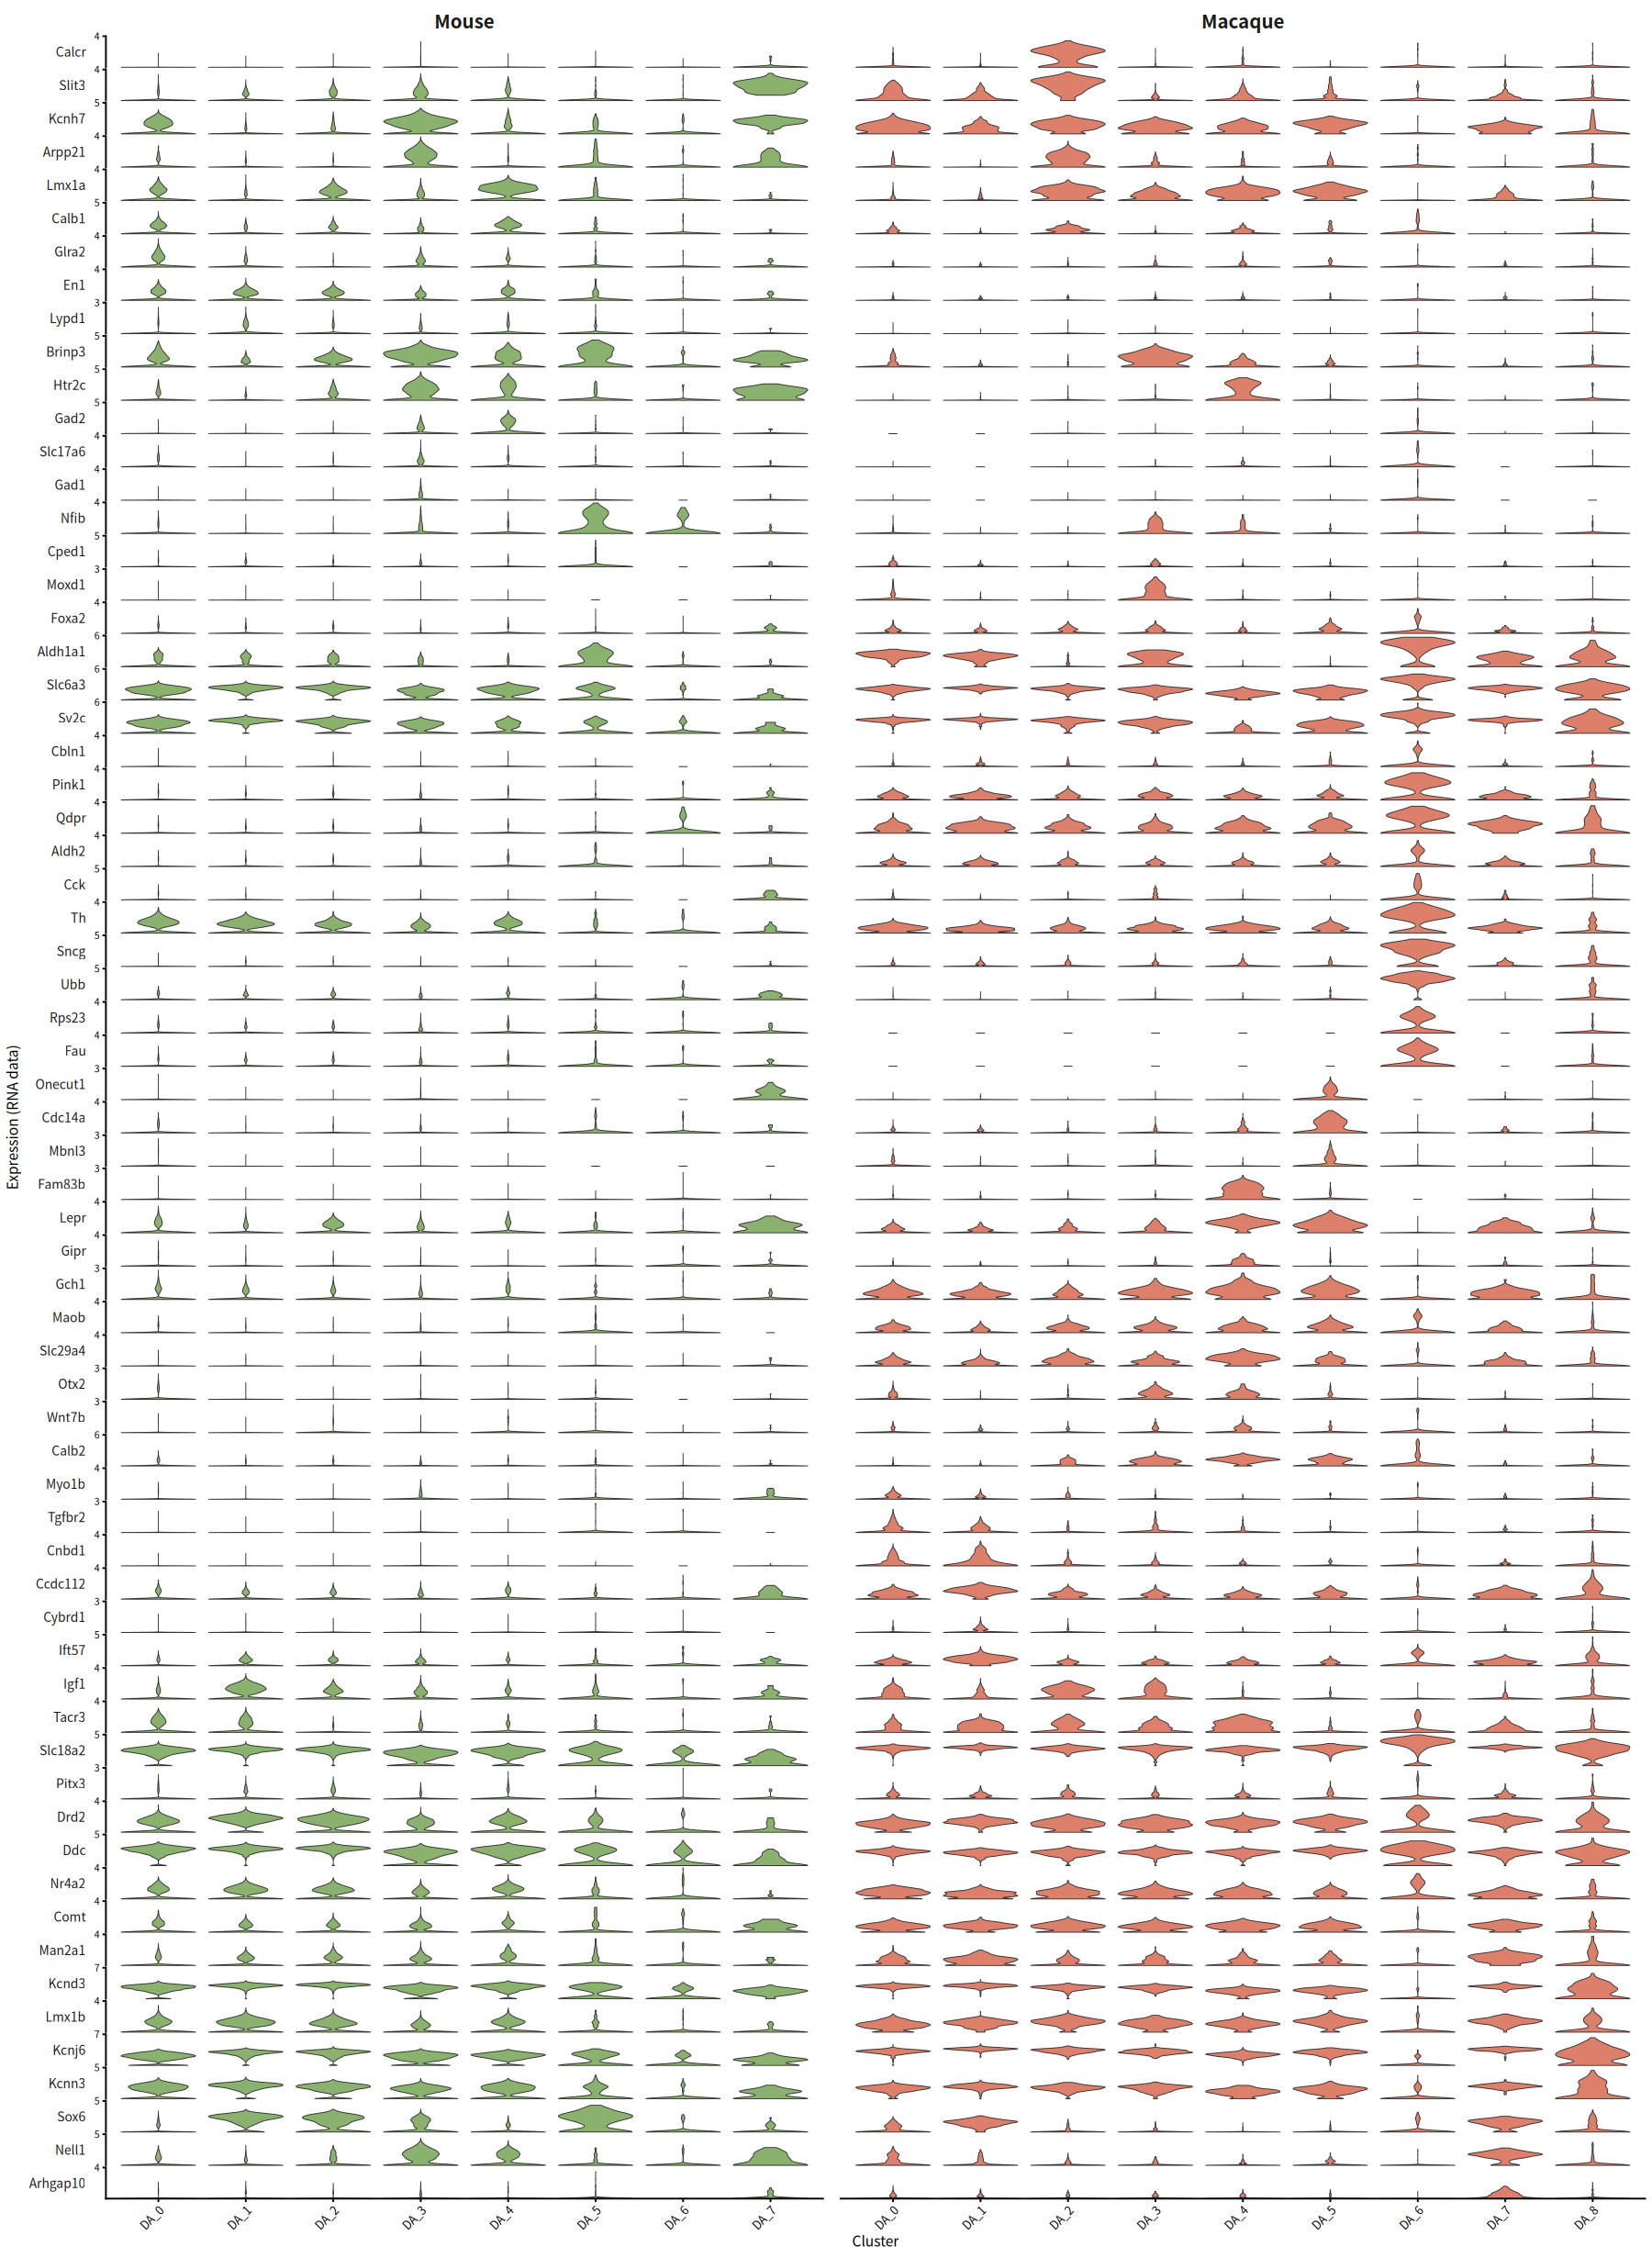

In [32]:
#%% 一次绘图：facet_grid 的同行面板共用 y 轴，按物种列分别保留各自的簇
violin_plot <- ggplot(plot_data, aes(cluster, expression, fill = species)) +
  geom_violin(data = plot_data[density_rows, , drop = FALSE],
    scale = 'width', trim = TRUE, linewidth = 0.2, width = 0.85) +
  geom_point(data = plot_data[constant_rows, , drop = FALSE], shape = 95, size = 3) +
  facet_grid(rows = vars(gene), cols = vars(species), scales = 'free',
    space = 'free_x', switch = 'y',
    labeller = labeller(species = species_labels, gene = gene_labels)) +
  scale_fill_manual(values = species_colors, breaks = species_order, drop = TRUE) +
  scale_y_continuous(limits = function(z) c(0, max(ceiling(z[2]), 1)),
    breaks = function(z) max(z), minor_breaks = NULL, expand = expansion(mult = c(0, 0))) +
  labs(x = 'Cluster', y = 'Expression (RNA data)') +
  theme_classic(base_size = 9, base_family = plot_font) +
  theme(legend.position = 'none', strip.background = element_blank(),
    strip.placement = 'outside', strip.text.x = element_text(face = 'bold', size = 12),
    strip.text.y.left = element_text(angle = 0, hjust = 1, size = 8),
    panel.spacing.x = grid::unit(0.8, 'lines'), panel.spacing.y = grid::unit(0.1, 'lines'),
    axis.text.x = element_text(angle = 45, hjust = 1), axis.text.y = element_text(size = 6))
violin_height <- max(3, length(gene_order) * gene_row_height + 1)
options(repr.plot.width = 15, repr.plot.height = violin_height)
print(violin_plot)

In [ ]:
#%% 保存图及核对信息；原来的 DEG 结果、RDS 和其他 notebook 不变
ggsave(file.path(out, 'mouse_macaque_shared_scale_violin.pdf'), violin_plot,
  width = violin_width, height = violin_height, units = 'in',
  device = grDevices::cairo_pdf, family = plot_font, limitsize = FALSE)
ggsave(file.path(out, 'mouse_macaque_shared_scale_violin.png'), violin_plot,
  width = violin_width, height = violin_height, units = 'in', dpi = 180,
  bg = 'white', limitsize = FALSE)
write.csv(gene_presence, file.path(out, 'original_gene_presence.csv'), row.names = FALSE)
write.csv(gene_scale, file.path(out, 'shared_gene_expression_ranges.csv'), row.names = FALSE)
write.csv(data.frame(row_order = seq_along(gene_order), gene = gene_order,
  label = unname(gene_labels[gene_order])), file.path(out, 'clustered_gene_order.csv'), row.names = FALSE)
write.csv(gene_mean_expression, file.path(out, 'gene_cluster_mean_expression.csv'), row.names = TRUE)
saveRDS(gene_clustering, file.path(out, 'gene_row_clustering.rds'))
cell_counts <- as.data.frame(table(species = plot_meta$species, cluster = plot_meta$cluster))
cell_counts <- cell_counts[cell_counts$Freq > 0, ]
write.csv(cell_counts, file.path(out, 'species_cluster_cell_counts.csv'), row.names = FALSE)
cat('结果已保存至：', out, '\n')